# Simple Linear Regression

Fit and interpret a one-predictor regression of salary on training hours.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid")

from pathlib import Path


def find_repo_root(start=Path.cwd()):
    for path in [start, *start.parents]:
        if (path / "pyproject.toml").exists():
            return path
    raise RuntimeError("Could not find repository root")


ROOT = find_repo_root()
DATA = ROOT / "data"

In [2]:
df = pd.read_csv(DATA / "career_outcomes.csv")
df.head()

,experience_years,education_years,training_hours,sector,remote,ai_tool_use,salary_k_eur,promoted
0,1.2,12,38.2,technology,0,4.8,60.2,0
1,5.1,16,20.7,technology,1,4.0,66.5,1
2,8.5,14,60.5,retail,0,8.2,76.5,1
3,9.7,16,38.7,finance,0,0.7,84.7,0
4,2.5,16,60.7,public,0,4.7,67.6,0


In [3]:
print(df.shape)
print(df.isna().sum())
df.describe()

(240, 8)
experience_years    0
education_years     0
training_hours      0
sector              0
remote              0
ai_tool_use         0
salary_k_eur        0
promoted            0
dtype: int64


,experience_years,education_years,training_hours,remote,ai_tool_use,salary_k_eur,promoted
count,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000,240.000000
mean,6.549167,15.591667,39.675417,0.350000,6.435833,75.679583,0.700000
std,3.702086,1.701566,16.086017,0.477966,2.215986,15.677923,0.459215
min,1.200000,12.000000,0.000000,0.000000,0.700000,36.200000,0.000000
25%,3.775000,14.000000,28.950000,0.000000,4.975000,64.725000,0.000000
50%,5.750000,16.000000,39.300000,0.000000,6.500000,74.450000,1.000000
75%,8.525000,16.000000,49.825000,1.000000,8.000000,86.525000,1.000000
max,18.600000,18.000000,90.000000,1.000000,10.000000,119.800000,1.000000


In [4]:
print((df["training_hours"] == 0).sum())
print((df["training_hours"] == 90).sum())
df.sort_values("training_hours").head(8)

3
1


,experience_years,education_years,training_hours,sector,remote,ai_tool_use,salary_k_eur,promoted
127,1.6,18,0.0,finance,0,2.5,62.4,0
65,6.5,14,0.0,finance,0,4.5,68.0,0
239,13.4,16,0.0,technology,0,1.4,75.0,1
198,6.4,16,5.1,finance,0,4.2,87.9,0
90,9.4,16,6.8,retail,0,6.5,73.7,1
134,13.3,16,7.1,technology,0,3.2,86.4,1
205,4.3,16,8.0,public,0,3.8,50.7,0
173,2.7,14,8.1,finance,0,3.6,52.9,0


In [5]:
df.sort_values("training_hours").tail(8)

,experience_years,education_years,training_hours,sector,remote,ai_tool_use,salary_k_eur,promoted
217,5.1,16,68.1,public,0,8.6,93.7,1
138,5.1,16,69.4,finance,0,6.1,79.1,1
196,5.7,18,70.1,finance,0,10.0,105.2,1
237,8.6,18,72.0,technology,0,9.5,114.6,1
104,5.4,12,72.9,retail,0,9.9,92.3,1
142,3.8,16,75.9,retail,0,9.9,74.8,1
38,2.9,18,79.7,finance,0,8.5,82.4,1
112,8.6,18,90.0,finance,0,10.0,88.0,1


## Analytic question

How much does salary tend to change with additional training hours? State the outcome, predictor, expected direction, and one plausible omitted variable.
It is strongly linked to training hours (correlation 0.62) and also linked to salary (correlation 0.40). Workers who use AI tools more may both take more training and earn more, so part of the slope may come from AI tool use and not from training. The slope may therefore be too large as an estimate of the effect of training.

[Text(0.5, 1.0, 'Salary and training hours'),
 Text(0.5, 0, 'Training hours'),
 Text(0, 0.5, 'Salary, thousand EUR')]

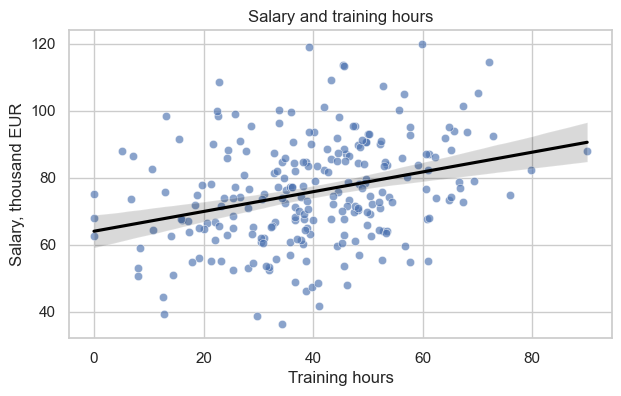

In [6]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=df, x="training_hours", y="salary_k_eur", alpha=0.65, ax=ax)
sns.regplot(data=df, x="training_hours", y="salary_k_eur", scatter=False, color="black", ax=ax)
ax.set(title="Salary and training hours", xlabel="Training hours", ylabel="Salary, thousand EUR")

In [7]:
model = smf.ols("salary_k_eur ~ training_hours", data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           salary_k_eur   R-squared:                       0.092
Model:                            OLS   Adj. R-squared:                  0.088
Method:                 Least Squares   F-statistic:                     24.02
Date:                Wed, 11 Nov 2026   Prob (F-statistic):           1.76e-06
Time:                        17:29:53   Log-Likelihood:                -989.05
No. Observations:                 240   AIC:                             1982.
Df Residuals:                     238   BIC:                             1989.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         63.9710      2.577     24.

In [8]:
intercept = model.params["Intercept"]
slope = model.params["training_hours"]
effect_per_hour = slope
print(f"Predicted salary with no training: {intercept:.1f} thousand EUR")
print(f"Estimated salary change per additional training hour: {effect_per_hour:.2f} thousand EUR")

Predicted salary with no training: 64.0 thousand EUR
Estimated salary change per additional training hour: 0.30 thousand EUR


In [9]:
new_workers = pd.DataFrame({"training_hours": [10, 40, 80]})
predictions = model.get_prediction(new_workers).summary_frame(alpha=0.05)
new_workers.join(predictions[["mean", "obs_ci_lower", "obs_ci_upper"]])

,training_hours,mean,obs_ci_lower,obs_ci_upper
0,10,66.922063,37.154695,96.689430
1,40,75.775371,46.216819,105.333924
2,80,87.579782,57.636773,117.522792


[Text(0.5, 1.0, 'Residuals versus fitted values'),
 Text(0.5, 0, 'Fitted salary'),
 Text(0, 0.5, 'Residual')]

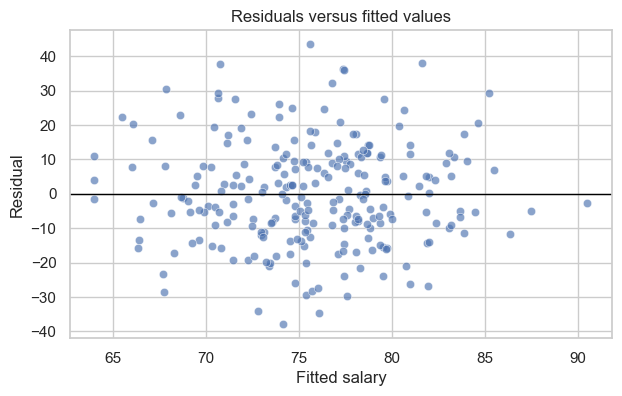

In [10]:
diagnostics = df.assign(fitted=model.fittedvalues, residual=model.resid)
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=diagnostics, x="fitted", y="residual", alpha=0.65, ax=ax)
ax.axhline(0, color="black", linewidth=1)
ax.set(title="Residuals versus fitted values", xlabel="Fitted salary", ylabel="Residual")

In [11]:
df[["training_hours", "ai_tool_use", "experience_years", "education_years", "salary_k_eur"]].corr().round(2)

,training_hours,ai_tool_use,experience_years,education_years,salary_k_eur
training_hours,1.00,0.62,-0.07,0.02,0.30
ai_tool_use,0.62,1.00,0.00,-0.03,0.40
experience_years,-0.07,0.00,1.00,0.10,0.57
education_years,0.02,-0.03,0.10,1.00,0.30
salary_k_eur,0.30,0.40,0.57,0.30,1.00


## Interpretation

State the slope as an association, with units, and name one omitted variable that could confound it.

Workers with one more training hour earn about 0.30 thousand EUR (about 295 EUR) more salary on average. This is an association, not proof of a cause. The 95% interval for the slope is 0.18 to 0.41 thousand EUR per hour. Training hours explain only about 9% of the differences in salary (R-squared = 0.09).

One omitted variable that could confound this is AI tool use. It is strongly linked to training hours (correlation 0.62) and also linked to salary (correlation 0.40). Workers who use AI tools more may both take more training and earn more, so part of the slope may come from AI tool use and not from training. The slope may therefore be too large as an estimate of the effect of training.